# From a Protégé ontology to modern AI

You have built an ontology in Protégé and saved it as an `.rdf` file. This notebook shows what you can do with it next, in the way ontologies are used in AI today.

| Step | What happens | Where this is used in practice |
|---|---|---|
| 1 | Load your `.rdf` file | Any tool that reads OWL |
| 2 | Run the **HermiT reasoner** and see the facts it adds | Clinical terminologies such as SNOMED CT |
| 3 | Turn the ontology into a **knowledge graph** | Google's Knowledge Graph, enterprise data platforms |
| 4 | Ask an LLM questions **with and without** the knowledge graph | GraphRAG, grounding LLMs in facts |
| 5 | Let the LLM suggest something and let the **reasoner check it** | AI guardrails |

Everything works on **your own ontology**. If you don't upload one, it uses the sample hospital ontology in this repo, which extends the doctor and patient example from the seminar. All patients in it are fictional, and the drug rules are simplified teaching examples, not medical advice.

### Before you start: a free Groq key (2 minutes)
Steps 4 and 5 use an open LLM served for free by **Groq**. By default that is OpenAI's open-weight model **gpt-oss-120b**, and the notebook picks another free model automatically if that one is unavailable.
1. Sign up at [console.groq.com](https://console.groq.com) and create an API key. No card is needed.
2. In Colab, click the **key icon** in the left sidebar, add a secret named `GROQ_API_KEY`, paste the key as its value and switch on **Notebook access**.

Steps 1 to 3 work without a key.

## Step 0. Setup
Installs the two libraries we need. `owlready2` reads OWL files and includes the HermiT reasoner, which runs on Java. `groq` talks to the LLM. Nothing else needs installing, because the model runs on Groq's servers.

In [26]:
!pip install -q owlready2 groq
!java -version 2>/dev/null || (apt-get -qq update && apt-get -qq install -y default-jre-headless > /dev/null)

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


In [27]:
import os, re, json, html, getpass, urllib.request
from owlready2 import *
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

# Your Groq key: Colab secret first, then an environment variable, then ask
GROQ_API_KEY = None
try:
    from google.colab import userdata
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except Exception:
    pass
GROQ_API_KEY = GROQ_API_KEY or os.environ.get("GROQ_API_KEY")
if not GROQ_API_KEY:
    GROQ_API_KEY = getpass.getpass("Paste your Groq API key (or press Enter to skip the AI steps): ").strip()
print("Groq key loaded ✓" if GROQ_API_KEY else "No Groq key. Steps 1 to 3 still work.")

Groq key loaded ✓


## Step 1. Load your ontology
In Protégé use **File → Save as… → RDF/XML Syntax**. Then drag the file into Colab's **Files** panel (folder icon on the left) and type its name below.

Leave `MY_FILE` empty to use the sample hospital ontology.

In [28]:
MY_FILE = ""   # e.g. "my_ontology.rdf"

SAMPLE_URL = "https://raw.githubusercontent.com/Thashmikab/Ontology_Testing/main/ontologies/hospital_ontology.rdf"
if MY_FILE:
    ONTO_PATH = MY_FILE
elif os.path.exists("ontologies/hospital_ontology.rdf"):
    ONTO_PATH = "ontologies/hospital_ontology.rdf"
else:
    ONTO_PATH = "hospital_ontology.rdf"
    urllib.request.urlretrieve(SAMPLE_URL, ONTO_PATH)
ONTO_PATH = os.path.abspath(ONTO_PATH)

onto = get_ontology("file://" + ONTO_PATH).load()

# helpers to print names without the long IRI prefixes
PREFIXES = {e.namespace.name for e in [*onto.classes(), *onto.properties(), *onto.individuals()]}
def nm(e):
    return e.name if hasattr(e, "name") else str(e)
def show(x):
    s = getattr(x, "__name__", None) if isinstance(x, type) and not isinstance(x, ThingClass) else None
    s = s or str(x)
    for p in PREFIXES:
        s = s.replace(p + ".", "")
    return s

IS_HOSPITAL = onto["pat_id_33"] is not None and onto["amoxicillin"] is not None
print(f"Loaded {os.path.basename(ONTO_PATH)}")
print(f"  {len(list(onto.classes()))} classes, {len(list(onto.object_properties()))} object properties, "
      f"{len(list(onto.data_properties()))} data properties, {len(list(onto.individuals()))} individuals")

Loaded hospital_ontology.rdf
  49 classes, 12 object properties, 1 data properties, 28 individuals


Here is the class hierarchy you built in Protégé.

In [29]:
def tree(c, depth=0):
    print("   " * depth + ("└─ " if depth else "") + nm(c))
    for sub in sorted(c.subclasses(), key=nm):
        tree(sub, depth + 1)

for top in sorted([c for c in onto.classes() if Thing in c.is_a], key=nm):
    tree(top)

Department
Disease
   └─ HeartDisease
      └─ CardiacArrhythmia
      └─ CoronaryArteryDisease
      └─ Hypertension
   └─ Injury
      └─ Arthritis
      └─ Fracture
      └─ Sprain
   └─ PulmonaryDisease
      └─ Asthma
      └─ COPD
      └─ Pneumonia
Medicine
   └─ Analgesic
   └─ Antibiotic
      └─ Macrolide
      └─ Penicillin
   └─ Anticoagulant
   └─ BetaBlocker
      └─ NonSelectiveBetaBlocker
      └─ SelectiveBetaBlocker
   └─ Bronchodilator
   └─ NSAID
Person
   └─ Doctor
      └─ Cardiologist
      └─ Orthopedic
      └─ Pulmonologist
   └─ Patient
      └─ HeartPatient
         └─ MultiMorbidPatient
      └─ Injured
      └─ MultiMorbidPatient
      └─ OlderPatient
         └─ OlderPatientNSAIDAlert
      └─ PenicillinAllergicPatient
      └─ PrescriptionAlert
         └─ BetaBlockerAsthmaAlert
         └─ BleedingRiskAlert
         └─ OlderPatientNSAIDAlert
      └─ PulmonaryPatient
         └─ BetaBlockerAsthmaAlert
         └─ MultiMorbidPatient
      └─ SuspectedHea

## Step 2. Run the reasoner
First we record every fact you wrote in Protégé. Then HermiT works out everything that **follows** from your classes, definitions and rules. Anything new is an **inferred** fact. Nobody typed it in.

In [30]:
def named_types(ind):
    return {c for c in ind.INDIRECT_is_a if isinstance(c, ThingClass) and c is not Thing}

def snapshot():
    types = {i: named_types(i) for i in onto.individuals()}
    direct = {i: [c for c in i.is_a if isinstance(c, ThingClass)] for i in onto.individuals()}
    rels = []
    for i in onto.individuals():
        for p in onto.object_properties():
            for v in p[i]:
                inv = p.inverse_property
                if isinstance(v, Thing) and not (inv and (nm(v), nm(inv), nm(i)) in rels):
                    rels.append((nm(i), nm(p), nm(v)))
        for p in onto.data_properties():
            for v in p[i]:
                rels.append((nm(i), nm(p), str(v)))
    return types, direct, rels

types_before, direct_before, rels_before = snapshot()

try:
    with onto:
        sync_reasoner(infer_property_values=True, debug=0)
    print("✓ The reasoner finished. Your ontology is consistent.")
except OwlReadyInconsistentOntologyError:
    raise SystemExit("✗ Your ontology is inconsistent. Open it in Protégé, run the reasoner and click the explanation to fix it.")

types_after, _, rels_after = snapshot()

# Build one numbered list of facts: what you wrote first, then what the reasoner added
FACTS = []
def add(s, p, o, inferred):
    FACTS.append({"id": f"F{len(FACTS) + 1}", "subject": s, "property": p, "object": o, "inferred": inferred})

for i in onto.individuals():
    for c in direct_before[i]:
        add(nm(i), "is a", nm(c), False)
for s, p, o in rels_before:
    add(s, p, o, False)
for i in onto.individuals():
    for c in sorted(types_after[i] - types_before[i], key=nm):
        add(nm(i), "is a", nm(c), True)
for s, p, o in rels_after:
    if (s, p, o) not in rels_before:
        add(s, p, o, True)

facts_df = pd.DataFrame(FACTS)
n_inf = int(facts_df.inferred.sum())
print(f"{len(facts_df) - n_inf} facts written in Protégé, {n_inf} facts added by the reasoner.")
display(facts_df[facts_df.inferred].drop(columns="inferred").reset_index(drop=True))

✓ The reasoner finished. Your ontology is consistent.
69 facts written in Protégé, 0 facts added by the reasoner.


,id,subject,property,object


> **Look at the table above.** Each row is something the computer worked out from your definitions.
> In the hospital sample, nobody wrote that `pat_id_12` is a `MultiMorbidPatient`, or that they should be referred to Cardiology.
> In your own ontology, check whether every inferred fact makes sense. A surprising one usually points to a domain or range you set too broadly.

## Step 3. The ontology as a knowledge graph
Individuals become **nodes** and property assertions become **links**. Grey links are what you wrote. **Orange dashed** links were inferred by the reasoner. This is the same data structure that sits behind Google's Knowledge Graph.

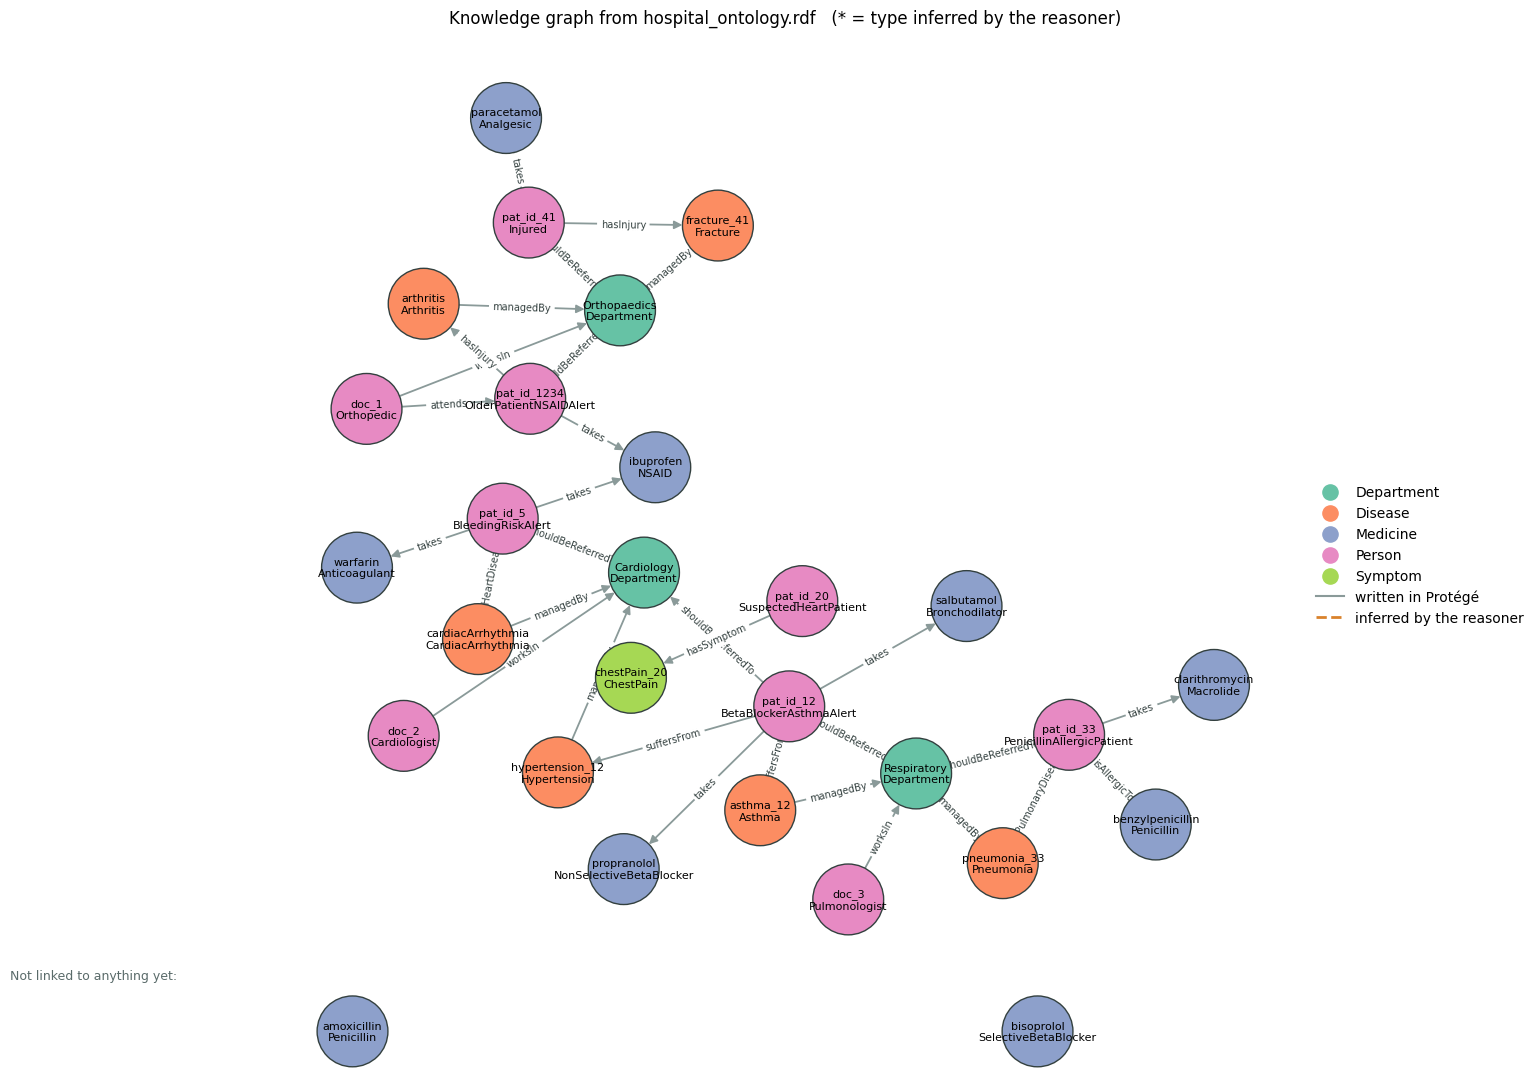

In [31]:
def root_class(i):
    ts = [c for c in types_after[i]]
    roots = [c for c in ts if not any(isinstance(p, ThingClass) and p is not Thing for p in c.is_a)]
    return nm(roots[0]) if roots else "Thing"

def label_type(i):
    new = types_after[i] - types_before[i]
    pool = new or set(direct_before[i])
    best = max(pool, key=lambda c: len(c.ancestors()), default=None)
    return (nm(best) if best else ""), bool(new)

G = nx.DiGraph()
for i in onto.individuals():
    G.add_node(nm(i))
for f in FACTS:
    if f["property"] != "is a" and f["object"] in G:
        G.add_edge(f["subject"], f["object"], label=f["property"], inferred=f["inferred"])

ind_by_name = {nm(i): i for i in onto.individuals()}
groups = sorted({root_class(i) for i in onto.individuals()})
palette = plt.cm.Set2.colors
colour = {g: palette[k % len(palette)] for k, g in enumerate(groups)}

und = G.to_undirected()
lonely = sorted(n for n in G if und.degree(n) == 0)          # nodes with no links go in a row underneath
core = und.subgraph([n for n in G if n not in lonely])
pos = {}
if core.number_of_nodes():
    pos = nx.kamada_kawai_layout(core) if core.number_of_edges() else nx.circular_layout(core)
    pos = nx.rescale_layout_dict(pos, scale=1)
    names = list(pos)
    for _ in range(300):                                     # nudge overlapping nodes apart
        moved = False
        for a in range(len(names)):
            for b in range(a + 1, len(names)):
                (xa, ya), (xb, yb) = pos[names[a]], pos[names[b]]
                dx, dy = xb - xa, yb - ya
                d = (dx * dx + dy * dy) ** 0.5
                if d < 0.24:
                    ux, uy = (dx / d, dy / d) if d > 1e-9 else (1.0, 0.0)
                    push = (0.24 - d) / 2
                    pos[names[a]] = (xa - ux * push, ya - uy * push)
                    pos[names[b]] = (xb + ux * push, yb + uy * push)
                    moved = True
        if not moved:
            break
low = min((y for _, y in pos.values()), default=0) - 0.3
for k, n in enumerate(lonely):
    pos[n] = (-1 + 2 * (k + 0.5) / len(lonely), low)
plt.figure(figsize=(16, 11))
asserted = [(u, v) for u, v, d in G.edges(data=True) if not d["inferred"]]
inferred = [(u, v) for u, v, d in G.edges(data=True) if d["inferred"]]
nx.draw_networkx_edges(G, pos, edgelist=asserted, edge_color="#8a9a99", width=1.3, arrows=True, arrowsize=12, node_size=2600)
nx.draw_networkx_edges(G, pos, edgelist=inferred, edge_color="#d9822b", width=2.2, style="dashed", arrows=True, arrowsize=14, node_size=2600)
nx.draw_networkx_nodes(G, pos, node_color=[colour[root_class(ind_by_name[n])] for n in G], node_size=2600, edgecolors="#33403f")
labels = {}
for n in G:
    t, new = label_type(ind_by_name[n])
    labels[n] = f"{n}\n{t}{' *' if new else ''}"
nx.draw_networkx_labels(G, pos, labels, font_size=8)
if G.number_of_edges() <= 45:
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), font_size=7, font_color="#33403f")
for g in groups:
    plt.scatter([], [], color=colour[g], s=120, label=g)
plt.plot([], [], color="#8a9a99", label="written in Protégé")
plt.plot([], [], color="#d9822b", linestyle="--", linewidth=2, label="inferred by the reasoner")
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=10, frameon=False)
if lonely:
    plt.text(-1, low + 0.12, "Not linked to anything yet:", fontsize=9, color="#5a6b6a")
plt.title("Knowledge graph from " + os.path.basename(ONTO_PATH) + "   (* = type inferred by the reasoner)", fontsize=12)
plt.axis("off"); plt.tight_layout()
plt.savefig("knowledge_graph.png", dpi=150)
plt.show()

## Step 4. Ask an LLM, with and without the knowledge graph
LLMs are fluent but they don't know **your** data, and they can confidently make things up. **GraphRAG** fixes this by sending the model the relevant facts from a knowledge graph and making it cite them. Here we ask the same question twice:

* **LLM on its own.** It only sees the question.
* **LLM + ontology.** It also gets your schema (classes, definitions, rules) and the facts that match the question, including the reasoner's inferred facts. It must cite fact numbers such as `[F12]`.

The **retrieval** step picks the facts that mention the things named in your question, plus their direct neighbours. That keeps the prompt small, which matters for large ontologies.

In [41]:

# ============================================================
# 1. GROQ MODEL SETUP
# ============================================================

MODEL = None
PREFERRED = ["openai/gpt-oss-120b", "openai/gpt-oss-20b", "qwen/qwen3.8-27b"]

client = None
if GROQ_API_KEY:
    from groq import Groq
    client = Groq(api_key=GROQ_API_KEY)

    if MODEL is None:
        try:
            available = {m.id for m in client.models.list().data}
        except Exception as e:
            available = set()
            print("Could not list Groq models:", e)

        MODEL = next((m for m in PREFERRED if m in available), None)
        if MODEL is None:
            chat = sorted(m for m in available if not re.search(
                r"whisper|tts|orpheus|guard|compound", m))
            MODEL = chat[0] if chat else PREFERRED[0]

    print("Using model:", MODEL)


# ============================================================
# 2. ASK THE LLM
# ============================================================

def ask_llm(prompt, json_mode=False, max_tokens=2000):
    if client is None:
        raise RuntimeError("No Groq API key. Check Colab secrets.")

    kw = dict(
        model=MODEL,
        temperature=0.2,
        max_tokens=max_tokens,
        messages=[{"role": "user", "content": prompt}]
    )

    if "gpt-oss" in MODEL:
        kw["reasoning_effort"] = "low"
    if json_mode:
        kw["response_format"] = {"type": "json_object"}

    for _ in range(3):
        try:
            r = client.chat.completions.create(**kw)
            break
        except Exception as e:
            msg = str(e).lower()
            if "reasoning" in msg and "reasoning_effort" in kw:
                kw.pop("reasoning_effort")
                continue
            if "response_format" in kw and ("json" in msg or "response_format" in msg):
                kw.pop("response_format")
                continue
            raise

    text = (r.choices[0].message.content or "").strip()
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()

    if not text:
        raise RuntimeError("The model returned an empty answer.")
    return text


def parse_json(text):
    m = re.search(r"\{.*\}", text, flags=re.S)
    return json.loads(m.group(0) if m else text)


# ============================================================
# 3. EXTRACT ONTOLOGY SCHEMA
# ============================================================

CHARACTERISTICS = (
    FunctionalProperty, InverseFunctionalProperty, TransitiveProperty,
    SymmetricProperty, AsymmetricProperty, ReflexiveProperty,
    IrreflexiveProperty
)

def schema_lines():
    L = []

    for c in sorted(onto.classes(), key=nm):
        parents = [nm(p) for p in c.is_a if isinstance(p, ThingClass) and p is not Thing]
        if parents:
            L.append(f"{nm(c)} is a subclass of {', '.join(parents)}")

        for e in c.equivalent_to:
            L.append(f"{nm(c)} is DEFINED as: {show(e)}")

        for r in c.is_a:
            if not isinstance(r, ThingClass):
                L.append(f"Every {nm(c)} must satisfy: {show(r)}")

    for d in onto.disjoint_classes():
        L.append("Disjoint: " + ", ".join(nm(x) for x in d.entities if isinstance(x, ThingClass)))

    for p in sorted(onto.properties(), key=nm):
        if isinstance(p, AnnotationPropertyClass):
            continue

        bits = []
        if p.domain:
            bits.append("domain " + ", ".join(show(x) for x in p.domain))
        if p.range:
            bits.append("range " + ", ".join(show(x) for x in p.range))

        chars = [s.__name__ for s in p.is_a if s in CHARACTERISTICS]
        if chars:
            bits.extend(chars)

        L.append(f"Property {nm(p)}: " + "; ".join(bits))

    return L


SCHEMA = schema_lines()

fact_line = lambda f: (
    f"[{f['id']}] {f['subject']} {f['property']} {f['object']}"
    + (" (inferred)" if f["inferred"] else "")
)


# ============================================================
# 4. RETRIEVE RELEVANT ONTOLOGY FACTS
# ============================================================

def words(name):
    spaced = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", name).replace("_", " ")
    return {name.lower(), spaced.lower()}


def retrieve(question, min_facts=6):
    q = question.lower()
    names = {f["subject"] for f in FACTS} | {f["object"] for f in FACTS}

    hits = {n for n in names if any(
        re.search(r"(?<!\w)" + re.escape(w) + r"(?!\w)", q)
        for w in words(n)
    )}

    first = [f for f in FACTS if f["subject"] in hits or f["object"] in hits]
    neighbours = {f["subject"] for f in first} | {f["object"] for f in first}
    second = [f for f in FACTS if f["subject"] in neighbours and f["property"] == "is a"]

    chosen = {f["id"] for f in first + second}
    picked = [f for f in FACTS if f["id"] in chosen]

    return (picked, sorted(hits)) if len(picked) >= min_facts else (FACTS, sorted(hits))


# ============================================================
# 5. CREATE PROMPTS
# ============================================================

def grounded_prompt(question, facts):
    return "\n".join([
        "Answer using ONLY the ontology knowledge graph below.",
        "Facts marked (inferred) were derived by the HermiT reasoner.",
        "Cite every fact using its ID, e.g. [F12].",
        "If information is missing, say it is not recorded. Do not guess.",
        "Answer in at most 110 words. Use plain text.",
        "", "SCHEMA:", *SCHEMA,
        "", "FACTS:", *[fact_line(f) for f in facts],
        "", "QUESTION: " + question
    ])


def plain_prompt(question):
    return f"Answer in at most 90 words, using plain text.\n\nQuestion: {question}"


# ============================================================
# 6. FORMAT FACT CITATIONS
# ============================================================

FACT_BY_ID = {f["id"]: f for f in FACTS}

def as_html(text, cite=False):
    t = html.escape(text).replace("\n", "<br>")

    if cite:
        def chip(m):
            f = FACT_BY_ID.get(m.group(1))
            if not f:
                return m.group(0)

            colour = "#ffe0a3" if f["inferred"] else "#b8e3d5"
            return (
                f"<span title='{html.escape(fact_line(f))}' "
                f"style='background:{colour};color:#263449;"
                f"border-radius:4px;padding:2px 5px;'>"
                f"{m.group(1)}</span>"
            )

        t = re.sub(r"(F\d+)", chip, t)

    return t


# ============================================================
# 7. COMPARE BOTH ANSWERS
# ============================================================

def compare(question):
    facts, hits = retrieve(question)

    print(f"Retrieved {len(facts)} of {len(FACTS)} facts")

    try:
        plain = ask_llm(plain_prompt(question))
        grounded = ask_llm(grounded_prompt(question, facts))
    except Exception as e:
        print("AI call failed:", e)
        return

    # Display both answers in separate coloured boxes
    display(HTML(f"""
    <div style="font-family:sans-serif;margin:10px 0;">
        <b>Question:</b> {html.escape(question)}
    </div>

    <div style="display:flex;gap:12px;flex-wrap:wrap;font-family:sans-serif;">

        <div style="flex:1;min-width:280px;padding:15px;
                    background:#263449;color:#ffffff;
                    border-radius:8px;line-height:1.6;">
            <b>LLM ON ITS OWN</b>
            <hr>
            {as_html(plain)}
        </div>

        <div style="flex:1;min-width:280px;padding:15px;
                    background:#123D38;color:#ffffff;
                    border-radius:8px;line-height:1.6;">
            <b>LLM + ONTOLOGY</b>
            <hr>
            {as_html(grounded, True)}
        </div>

    </div>
    """))

    # Show the facts used in the ontology-based answer
    used = [FACT_BY_ID[i] for i in dict.fromkeys(
        re.findall(r"F\d+", grounded)) if i in FACT_BY_ID]

    if used:
        print("\nFacts used in the grounded answer:")
        for f in used:
            print(" ", fact_line(f))

        inferred = sum(f["inferred"] for f in used)
        if inferred:
            print(f"{inferred} facts were inferred by the reasoner.")


print(f"Schema: {len(SCHEMA)} lines. Knowledge graph: {len(FACTS)} facts.")


Using model: openai/gpt-oss-120b
Schema: 78 lines. Knowledge graph: 69 facts.


Run the comparison. To use your own ontology, write your own question in `QUESTION`.

In [42]:
QUESTION = "Which patients should be referred to Cardiology, and which doctor works there?"

if not IS_HOSPITAL and "Cardiology" in QUESTION:
    some = nm(list(onto.individuals())[0])
    QUESTION = f"What does the knowledge graph say about {some}?"   # change this to your own question
compare(QUESTION)

Retrieved 13 of 69 facts



Facts used in the grounded answer:
  [F46] pat_id_5 shouldBeReferredTo Cardiology
  [F55] pat_id_12 shouldBeReferredTo Cardiology
  [F14] doc_2 is a Cardiologist
  [F35] doc_2 worksIn Cardiology


Two more questions for the hospital sample. The first shows a **safety** difference. The second shows the **open-world assumption**, where the grounded model should say the fact is not recorded instead of saying no.

In [43]:
if IS_HOSPITAL:
    compare("Can pat_id_33 be given amoxicillin?")

Retrieved 12 of 69 facts



Facts used in the grounded answer:
  [F29] pat_id_33 is a PenicillinAllergicPatient
  [F62] pat_id_33 isAllergicTo benzylpenicillin
  [F4] amoxicillin is a Penicillin


In [44]:
if IS_HOSPITAL:
    compare("Does pat_id_41 have heart disease?")

Retrieved 8 of 69 facts


## Step 5. The LLM suggests, the reasoner checks
LLMs can be useful, but they shouldn't have the last word. Here the LLM proposes a **new fact**, we add it to a copy of the ontology, and HermiT checks it against every rule.

* **Blocked** means the new fact makes the ontology inconsistent.
* **New inferences** means it's allowed, but the reasoner concludes something new, such as an alert.
* **No rule triggered** means nothing in the ontology objects.

`check_new_fact` works on any ontology. Use `"is a"` as the property to test a new type.

In [45]:
def check_new_fact(s, p, o, quiet=False):
    w = World()
    o2 = w.get_ontology("file://" + ONTO_PATH).load()
    subj = o2[s]
    if subj is None:
        raise ValueError(f"No individual called {s}")
    with o2:
        if p == "is a":
            subj.is_a.append(o2[o])
        else:
            prop = o2[p]
            target = o2[o] if o2[o] is not None else (int(o) if str(o).isdigit() else o)
            getattr(subj, p).append(target)
    before = {nm(c) for c in types_after[ind_by_name[s]]}
    try:
        with o2:
            sync_reasoner(w, infer_property_values=True, debug=0)
    except OwlReadyInconsistentOntologyError:
        result = {"verdict": "BLOCKED", "new": []}
    else:
        after = {nm(c) for c in subj.INDIRECT_is_a if isinstance(c, ThingClass) and c is not Thing}
        new = sorted(after - before)
        result = {"verdict": "NEW INFERENCES" if new else "NO RULE TRIGGERED", "new": new}
    if not quiet:
        colour = {"BLOCKED": "#b42318", "NEW INFERENCES": "#a8650c", "NO RULE TRIGGERED": "#1e7a3c"}[result["verdict"]]
        extra = ("<br>The reasoner now also concludes: <b>" + ", ".join(result["new"]) + "</b>") if result["new"] else ""
        if result["verdict"] == "BLOCKED":
            extra = "<br>Adding this makes the ontology <b>inconsistent</b>."
        display(HTML(f"<div style='font-family:sans-serif;border:2px solid {colour};border-radius:10px;padding:10px 14px;margin:6px 0'>"
                     f"<div style='font-size:20px;color:{colour};font-weight:600'>{result['verdict']}</div>"
                     f"<code>{html.escape(f'{s} {p} {o}')}</code>{extra}</div>"))
    return result

def explain_block(s, p, o):
    facts, _ = retrieve(f"{s} {o}")
    prompt = "\n".join([
        f"The HermiT reasoner says that adding the fact '{s} {p} {o}' makes this ontology inconsistent.",
        "Using ONLY the schema and facts below, explain why in at most 3 short bullets. Cite fact ids like [F12] and name the schema rule.",
        "", "SCHEMA:", *SCHEMA, "", "FACTS:", *[fact_line(f) for f in facts]])
    display(HTML("<div style='font-family:sans-serif;font-size:14px;line-height:1.5'><b>The LLM explains the reasoner's decision:</b><br>"
                 + as_html(ask_llm(prompt), True) + "</div>"))

In [46]:
if IS_HOSPITAL:
    PATIENT = "pat_id_33"
    p = ind_by_name[PATIENT]
    diagnoses = sorted({nm(v.is_a[0]) for prop in onto.object_properties() for v in prop[p] if isinstance(v, onto.Disease)})
    formulary = {nm(m).lower(): nm(m) for m in onto.Medicine.instances()}
    menu = ", ".join(f"{nm(m)} ({nm(m.is_a[0])})" for m in onto.Medicine.instances())

    # The LLM only gets the diagnosis, like a quick chatbot query. The patient record stays in the ontology.
    ask = (f'A doctor says: "My patient has {" and ".join(diagnoses)}. Pick ONE medicine from our formulary to start treatment." '
           f"Formulary: {menu}. Reply with only JSON: {{\"medicine\": \"<exact name>\", \"reason\": \"<max 20 words>\"}}")
    try:
        reply = parse_json(ask_llm(ask, json_mode=True, max_tokens=1500))
        med = formulary.get(str(reply.get("medicine", "")).lower().strip())
        print(f"The LLM suggests: {reply.get('medicine')}  ({reply.get('reason')})")
        if med:
            r = check_new_fact(PATIENT, "takes", med)
            if r["verdict"] == "BLOCKED":
                explain_block(PATIENT, "takes", med)
        else:
            print("That medicine isn't in the ontology, so the reasoner cannot check it.")
    except Exception as e:
        print("The AI call failed:", e)

The LLM suggests: amoxicillin  (Effective first-line treatment for typical bacterial pneumonia)


You can also check facts yourself. These run the reasoner only, so they need no key.

In [47]:
if IS_HOSPITAL:
    check_new_fact("pat_id_33", "takes", "amoxicillin")      # penicillin allergy
    check_new_fact("pat_id_33", "takes", "clarithromycin")   # a macrolide, so no conflict
    check_new_fact("pat_id_1234", "takes", "warfarin")       # warfarin plus ibuprofen at age 71
else:
    print("Try a fact from your own ontology, for example:")
    print('check_new_fact("John", "is a", "Lecturer")   # inconsistent if Student and Lecturer are disjoint')

## What you just did
1. **Reasoning.** HermiT added facts that follow from your definitions. Clinical systems built on SNOMED CT classify records in the same way.
2. **Knowledge graph.** Your ontology became a graph of linked facts, the structure behind search engines and enterprise data platforms.
3. **GraphRAG.** The LLM answered from your facts, cited them and admitted when something was not recorded. Without them it could only guess.
4. **Guardrail.** The reasoner checked an AI suggestion against hard rules and explained the result. This is how symbolic AI makes machine learning systems safer.

### Try next
* Run the notebook on **your own** `.rdf` and write questions that need an inferred fact to answer.
* Add a defined class (an *equivalent to* definition) in Protégé, save, and see what new facts the reasoner adds.
* Add a disjointness axiom and use `check_new_fact` to catch a mistake.
* Set `MODEL = "openai/gpt-oss-20b"` in Step 4 and compare how well a smaller model sticks to the facts.

*Made by [Thashmika Bandara](https://github.com/Thashmikab). If this helped, a ⭐ on the repo is appreciated.*